In [1]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [2]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [3]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):
    """
    Detector energy resolution model.
    Returns sigma in keV.
    """
    A = 3.68436e1
    B = 1.72714e4

    return (E * np.sqrt(A / E + B / E**2)) / 2.355 / 100
    


In [4]:

def add_peak(ax, x, text, y_text, y_line_top=150):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 2, y_text),
        rotation=90,
        fontsize=11
    )

In [5]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [6]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, counts



In [7]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [8]:
# ============================================================
# PEAK FITTING
# ============================================================
def fit_peak(E, counts, center, window=4, plot=True):
    """
    Fit a Gaussian peak + constant background.
    """

    mask = (E > center - window) & (E < center + window)

    E_roi = E[mask]
    counts_roi = counts[mask]

    sigma_guess = sigma_fun(center)

    p0 = [
        center,
        sigma_guess,
        np.sum(counts_roi),
        np.median(counts_roi),
    ]

    bounds = (
        [center - 1, 0.01, 0, 0],
        [center + 1, 10, np.inf, np.inf],
    )

    popt, pcov = curve_fit(
        gaussian_plus_bg,
        E_roi,
        counts_roi,
        p0=p0,
        bounds=bounds,
        #sigma=np.sqrt(counts_roi),
        maxfev=10000,
    )

    perr = np.sqrt(np.diag(pcov))

    result = {
        "mu": popt[0],
        "sigma": popt[1],
        "N": popt[2],
        "B": popt[3],
        "err_mu": perr[0],
        "err_sigma": perr[1],
        "err_N": perr[2],
        "err_B": perr[3],
    }

    if plot:
        fig, ax = plt.subplots(
            2,
            1,
            figsize=(7, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
        )

        E_fit = np.linspace(E_roi.min(), E_roi.max(), 400)
        model_fit = gaussian_plus_bg(E_fit, *popt)

        ax[0].step(E_roi, counts_roi, where="mid", color="black", label="Data")
        ax[0].plot(E_fit, model_fit, color="red", lw=2, label="Fit")

        ax[0].set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")
        ax[0].set_title(f"Peak @ {center:.2f} keV")
        ax[0].legend()
        ax[0].grid(alpha=0.3)

        residuals = counts_roi - gaussian_plus_bg(E_roi, *popt)

        ax[1].scatter(E_roi, residuals, s=15)
        ax[1].axhline(0, color="red")
        ax[1].set_xlabel("Energy [keV]")
        ax[1].set_ylabel("Residuals")
        ax[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    return result


In [9]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, total_counts, total_time

In [10]:
# ============================================================
# CONFIGURATION
# ============================================================
FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "60d": {
        "path": "csv-files/run3.csv",
        "time": 5151460,
        "calibration": {
            "a": 4.17351849e-01,
            "b": 5.03999145e-01,
            "c": 1.19722147e-07,
        },
    },
}

In [20]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.4

SIGNAL = {
    "mu_96Zr": 778.2,
    "mu_94Zr": 841.2,
    "roi": (750, 920),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [21]:
# ============================================================
# MAIN DATA PREPARATION
# ============================================================
BINS = np.arange(
    ENERGY_RANGE[0],
    ENERGY_RANGE[1] + BIN_WIDTH,
    BIN_WIDTH
)

E_tot, Ntot, t_tot = build_total_spectrum(FILES, BINS)

print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)


Total counts = 24456 in 109.2 days


In [22]:
BACKGROUND_PEAKS = {
   "???" : {"E":860.45, "N":0},
    "207Tl":  {"E":897.77, "N":0},
    "228Ac":  {"E":911.204, "N":0},
    "95Zr": {"E": 756.73, "N": 6.5},
    "214Bi": {"E": 768.4, "N": 5.11},
    "95Nb": {"E": 765.8, "N": 18},
    '???': {"E": 784.5, "N" : 0},
    "228Ac": {"E": 794.947, "N": 3.55}
}


In [23]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

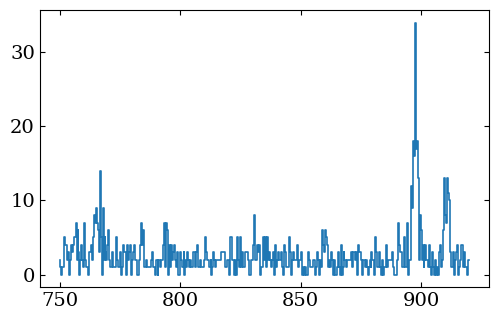

In [24]:
plt.step(E_roi, counts_roi)

In [25]:


# ============================================================
# BINNING
# ============================================================
bin_edges = BINS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ============================================================
# ROI SELECTION (SAFE: on bin centers)
# ============================================================
roi_mask = (
    (bin_centers >= SIGNAL["roi"][0]) &
    (bin_centers <= SIGNAL["roi"][1])
)

counts_roi = Ntot[roi_mask]

idx = np.where(roi_mask)[0]
bin_edges_roi = bin_edges[idx[0]:idx[-1] + 2]


In [80]:
edges_low = bin_edges_roi[:-1]
edges_high = bin_edges_roi[1:]
bin_width = edges_high - edges_low
E_center = 0.5 * (edges_low + edges_high)

# ============================================================
# CDF GAUSSIAN (PyTensor safe)
# ============================================================
def gaussian_cdf(x, mu, sigma):
    return 0.5 * (1.0 + pt.erf((x - mu) / (sigma * pt.sqrt(2.0))))

def bin_integral(mu, sigma, low, high):
    return gaussian_cdf(high, mu, sigma) - gaussian_cdf(low, mu, sigma)


# ============================================================
# MODEL
# ============================================================
with pm.Model() as model:

    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================
    A_bg = []
    mu_bg = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        A = pm.HalfNormal(f"A_{name}", sigma=np.max(counts_roi)/2)
        mu = pm.Normal(f"mu_{name}", mu=fit["E"], sigma=0.3)

        A_bg.append(A)
        mu_bg.append(mu)

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)

    # ========================================================
    # SIGNAL 96Zr
    # ========================================================
    A_96Zr = pm.HalfNormal("A_96Zr", sigma=np.max(counts_roi))
    mu_96Zr = pm.Normal("mu_96Zr", mu=SIGNAL["mu_96Zr"], sigma=0.3)

    sigma_96Zr = pm.Deterministic("sigma_96Zr", sigma_fun(mu_96Zr))

    sig_96Zr = bin_integral(
        mu_96Zr,
        sigma_96Zr,
        edges_low,
        edges_high
    )

    # ========================================================
    # SIGNAL 94Zr
    # ========================================================
    A_94Zr = pm.HalfNormal("A_94Zr", sigma=np.max(counts_roi))
    mu_94Zr = pm.Normal("mu_94Zr", mu=SIGNAL["mu_94Zr"], sigma=0.3)

    sigma_94Zr = pm.Deterministic("sigma_94Zr", sigma_fun(mu_94Zr))

    sig_94Zr = bin_integral(
        mu_94Zr,
        sigma_94Zr,
        edges_low,
        edges_high
    )

    # ========================================================
    # LINEAR BACKGROUND (IMPORTANT CHANGE)
    # ========================================================
    Q = pm.HalfNormal("Q", sigma=np.median(counts_roi))
    

    Q_bins = Q * bin_width

    # ========================================================
    # BACKGROUND PEAK INTEGRALS (FIXED BUG)
    # ========================================================
    bg = pt.stack([
        bin_integral(
            mu_bg[i],
            sigma_fun(mu_bg[i]),
            edges_low,
            edges_high
        )
        for i in range(len(BACKGROUND_PEAKS))
    ])

    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================
    lambda_E = (
        Q_bins
        + A_96Zr * sig_96Zr
        + A_94Zr * sig_94Zr
        + pt.sum(A_bg[:, None] * bg, axis=0)
    )

    lambda_E = pt.clip(lambda_E, 1e-9, np.inf)

    # ========================================================
    # LIKELIHOOD
    # ========================================================
    pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi
    )

    # ========================================================
    # SAMPLING
    # ========================================================
    trace = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.95,
        init="jitter+adapt_diag",
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_???, mu_???, A_207Tl, mu_207Tl, A_228Ac, mu_228Ac, A_95Zr, mu_95Zr, A_214Bi, mu_214Bi, A_95Nb, mu_95Nb, A_96Zr, mu_96Zr, A_94Zr, mu_94Zr, Q]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 19 seconds.


In [81]:
summary = az.summary(trace, round_to=4)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_???,784.4858,0.2386,784.0442,784.9362,0.0021,0.0032,13536.1167,5388.2412,1.0005
mu_207Tl,897.8175,0.1045,897.6225,898.0177,0.0009,0.0014,15020.8114,5189.9917,1.0000
mu_228Ac,794.7774,0.2647,794.3084,795.3102,0.0024,0.0034,12664.7658,5219.6425,1.0001
mu_95Zr,756.7054,0.2376,756.2631,757.1458,0.0020,0.0032,14502.2873,4926.7832,1.0006
mu_214Bi,768.3272,0.2941,767.7904,768.8858,0.0027,0.0033,12197.4720,6089.3631,1.0001
mu_95Nb,765.6829,0.2184,765.2612,766.0849,0.0020,0.0027,11830.0243,5759.6262,1.0004
mu_96Zr,778.2085,0.2957,777.6627,778.7742,0.0025,0.0039,13548.8446,5760.2758,1.0012
mu_94Zr,841.1925,0.2969,840.6440,841.7496,0.0024,0.0038,14825.0565,5788.0257,1.0015
A_???,10.6135,4.8778,1.4926,19.4226,0.0551,0.0632,5817.9007,2497.6641,1.0001
A_207Tl,92.0669,8.0339,77.5790,107.8371,0.0728,0.1098,12104.8946,4948.9578,1.0012


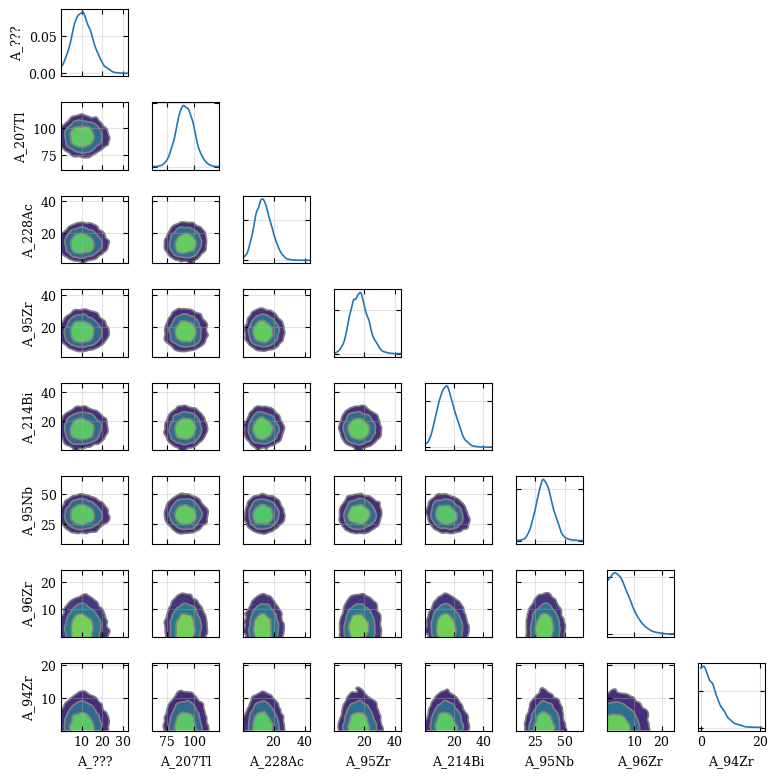

In [82]:

# ============================================================
# CORRELATION PLOTS
# ============================================================
A_vars = [v for v in trace.posterior.data_vars if v.startswith("A_")]

axes = az.plot_pair(
    trace,
    var_names=A_vars,
    kind="kde",
    marginals=True,
    figsize=(8, 8),
    textsize=9,
)

for ax in axes.flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.show()


In [83]:
signal96_samples = trace.posterior["A_96Zr"].values.flatten()

N96_90 = np.percentile(signal96_samples, 90)
N96_95 = np.percentile(signal96_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on 96Zr counts : {N96_90:.3f}")
print(f"95% upper limit on 96Zr counts : {N96_95:.3f}")
print("=" * 60)





90% upper limit on 96Zr counts : 10.905
95% upper limit on 96Zr counts : 12.928


In [84]:
signal94_samples = trace.posterior["A_94Zr"].values.flatten()

N94_90 = np.percentile(signal94_samples, 90)
N94_95 = np.percentile(signal94_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on 94Zr counts : {N94_90:.3f}")
print(f"95% upper limit on 94Zr counts : {N94_95:.3f}")
print("=" * 60)


90% upper limit on 94Zr counts : 8.206
95% upper limit on 94Zr counts : 9.980


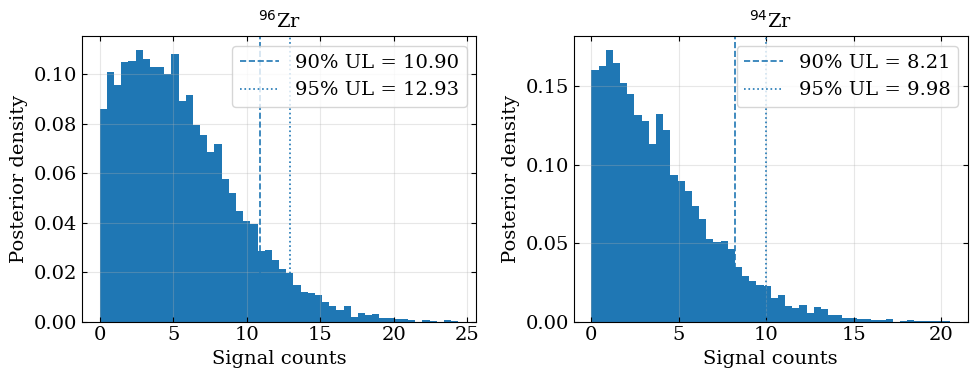

In [85]:
# ============================================================
# EXTRACT POSTERIORS
# ============================================================
signal96_samples = trace.posterior["A_96Zr"].values.flatten()
signal94_samples = trace.posterior["A_94Zr"].values.flatten()

# ============================================================
# UPPER LIMITS
# ============================================================
N96_90 = np.percentile(signal96_samples, 90)
N96_95 = np.percentile(signal96_samples, 95)

N94_90 = np.percentile(signal94_samples, 90)
N94_95 = np.percentile(signal94_samples, 95)

# ============================================================
# FIGURE
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(10, 4)
)

# ============================================================
# 96Zr
# ============================================================
ax1.hist(
    signal96_samples,
    bins=50,
    density=True
)

ax1.axvline(
    N96_90,
    linestyle="--",
    label=f"90% UL = {N96_90:.2f}"
)

ax1.axvline(
    N96_95,
    linestyle=":",
    label=f"95% UL = {N96_95:.2f}"
)

ax1.set_title(r"$^{96}$Zr")
ax1.set_xlabel("Signal counts")
ax1.set_ylabel("Posterior density")

ax1.grid(alpha=0.3)
ax1.legend()

# ============================================================
# 94Zr
# ============================================================
ax2.hist(
    signal94_samples,
    bins=50,
    density=True
)

ax2.axvline(
    N94_90,
    linestyle="--",
    label=f"90% UL = {N94_90:.2f}"
)

ax2.axvline(
    N94_95,
    linestyle=":",
    label=f"95% UL = {N94_95:.2f}"
)

ax2.set_title(r"$^{94}$Zr")
ax2.set_xlabel("Signal counts")
ax2.set_ylabel("Posterior density")

ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

In [86]:
background_names = list(BACKGROUND_PEAKS.keys())

background_energies = np.array([
    BACKGROUND_PEAKS[name]["E"] for name in background_names
])

background_sigmas = sigma_fun(background_energies)


In [87]:
# ============================================================
# EXTRACT POSTERIOR
# ============================================================
idata = trace
posterior = idata.posterior

Q_s = posterior["Q"].values.reshape(-1)

A_96_s = posterior["A_96Zr"].values.reshape(-1)
A_94_s = posterior["A_94Zr"].values.reshape(-1)

mu_96_s = posterior["mu_96Zr"].values.reshape(-1)
mu_94_s = posterior["mu_94Zr"].values.reshape(-1)

A_bg_s = {
    name: posterior[f"A_{name}"].values.reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"].values.reshape(-1)
    for name in background_names
}

# ============================================================
# GRID
# ============================================================
bin_centers = 0.5 * (BINS[:-1] + BINS[1:])

roi_mask = (
    (bin_centers >= SIGNAL["roi"][0])
    &
    (bin_centers <= SIGNAL["roi"][1])
)

E_roi = bin_centers[roi_mask]
counts_roi = Ntot[roi_mask]

E_fine = np.linspace(
    E_roi.min(),
    E_roi.max(),
    3000
)

# ============================================================
# GAUSSIAN
# ============================================================
def gaussian(x, mu, sigma):

    return (
        1.0
        /
        (np.sqrt(2*np.pi) * sigma)
    ) * np.exp(
        -0.5 * ((x - mu)/sigma)**2
    )

# ============================================================
# TOTAL MODEL
# ============================================================
def build_total(E, i):

    lam = (
        Q_s[i]
        * BIN_WIDTH
        * np.ones_like(E)
    )

    # background peaks
    for name in background_names:

        mu_i = mu_bg_s[name][i]
        sigma_i = sigma_fun(mu_i)

        lam += (
            A_bg_s[name][i]
            * gaussian(E, mu_i, sigma_i)
        )

    # 96Zr
    lam += (
        A_96_s[i]
        * gaussian(
            E,
            mu_96_s[i],
            sigma_fun(mu_96_s[i])
        )
    )

    # 94Zr
    lam += (
        A_94_s[i]
        * gaussian(
            E,
            mu_94_s[i],
            sigma_fun(mu_94_s[i])
        )
    )

    return lam

# ============================================================
# BACKGROUND ONLY
# ============================================================
def build_background(E, i):

    lam = (
        Q_s[i]
        * BIN_WIDTH
        * np.ones_like(E)
    )

    for name in background_names:

        mu_i = mu_bg_s[name][i]
        sigma_i = sigma_fun(mu_i)

        lam += (
            A_bg_s[name][i]
            * gaussian(E, mu_i, sigma_i)
        )

    return lam

# ============================================================
# DRAWS
# ============================================================
lambda_draws = np.array([
    build_total(E_roi, i)
    for i in range(len(Q_s))
])

lambda_fine_draws = np.array([
    build_total(E_fine, i)
    for i in range(len(Q_s))
])

lambda_bkg_fine_draws = np.array([
    build_background(E_fine, i)
    for i in range(len(Q_s))
])

# ============================================================
# TOTAL MODEL STATISTICS
# ============================================================
lambda_mean = np.mean(
    lambda_draws,
    axis=0
)

lambda_low = np.percentile(
    lambda_draws,
    16,
    axis=0
)

lambda_high = np.percentile(
    lambda_draws,
    84,
    axis=0
)

# ============================================================
# FINE GRID MODEL
# ============================================================
lambda_fine_mean = np.mean(
    lambda_fine_draws,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_fine_draws,
    16,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_fine_draws,
    84,
    axis=0
)

# ============================================================
# BACKGROUND COMPONENT
# ============================================================
lambda_bkg_fine_mean = np.mean(
    lambda_bkg_fine_draws,
    axis=0
)

lambda_bkg_fine_low = np.percentile(
    lambda_bkg_fine_draws,
    16,
    axis=0
)

lambda_bkg_fine_high = np.percentile(
    lambda_bkg_fine_draws,
    84,
    axis=0
)

# ============================================================
# TRUE POSTERIOR PREDICTIVE
# ============================================================
with model:

    ppc = pm.sample_posterior_predictive(
        trace,
        var_names=["obs"],
        random_seed=42
    )

rep = ppc.posterior_predictive["obs"].values

rep_flat = rep.reshape(
    -1,
    rep.shape[-1]
)

# ============================================================
# PPC STATISTICS
# ============================================================
mean_rep = np.mean(
    rep_flat,
    axis=0
)

std_rep = np.std(
    rep_flat,
    axis=0
)

# ============================================================
# PPC PULLS
# ============================================================
residuals = (
    counts_roi
    -
    mean_rep
) / (std_rep + 1e-9)

# ============================================================
# COVERAGE
# ============================================================
low68, high68 = np.percentile(
    rep_flat,
    [16, 84],
    axis=0
)

coverage68 = (
    (
        counts_roi >= low68
    )
    &
    (
        counts_roi <= high68
    )
).mean()

low95, high95 = np.percentile(
    rep_flat,
    [2.5, 97.5],
    axis=0
)

coverage95 = (
    (
        counts_roi >= low95
    )
    &
    (
        counts_roi <= high95
    )
).mean()

print()
print("=" * 60)
print(f"68% coverage : {coverage68:.3f}")
print(f"95% coverage : {coverage95:.3f}")
print("=" * 60)

# ============================================================
# SIGNAL LIMITS
# ============================================================
N96_90 = np.percentile(A_96_s, 90)
N96_95 = np.percentile(A_96_s, 95)

N94_90 = np.percentile(A_94_s, 90)
N94_95 = np.percentile(A_94_s, 95)

print()
print("=" * 60)
print(f"96Zr 90% UL : {N96_90:.3f}")
print(f"96Zr 95% UL : {N96_95:.3f}")
print()
print(f"94Zr 90% UL : {N94_90:.3f}")
print(f"94Zr 95% UL : {N94_95:.3f}")
print("=" * 60)

Sampling: [obs]


Output()


68% coverage : 0.767
95% coverage : 0.958

96Zr 90% UL : 10.905
96Zr 95% UL : 12.928

94Zr 90% UL : 8.206
94Zr 95% UL : 9.980


In [88]:
# ============================================================
# POSTERIOR PREDICTIVE (CORRETTO)
# ============================================================
with model:
    ppc = pm.sample_posterior_predictive(
        trace,
        var_names=["obs"],
        random_seed=42
    )

rep = ppc.posterior_predictive["obs"].values
rep_flat = rep.reshape(-1, rep.shape[-1])

# ============================================================
# PPC STATISTICS
# ============================================================
mean_rep = rep_flat.mean(axis=0)
std_rep  = rep_flat.std(axis=0)

# ============================================================
# COVERAGE
# ============================================================
low95, high95 = np.percentile(
    rep_flat,
    [2.5, 97.5],
    axis=0
)

coverage95 = (
    (counts_roi >= low95)
    &
    (counts_roi <= high95)
).mean()

low68, high68 = np.percentile(
    rep_flat,
    [16, 84],
    axis=0
)

coverage68 = (
    (counts_roi >= low68)
    &
    (counts_roi <= high68)
).mean()

print("68% coverage:", coverage68)
print("95% coverage:", coverage95)

# ============================================================
# RESIDUALS (PPC PULLS)
# ============================================================
residuals = (
    counts_roi - mean_rep
) / (std_rep + 1e-9)

# ============================================================
# TOTAL MODEL BAND
# ============================================================
lambda_total_mean = np.mean(
    lambda_fine_draws,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_fine_draws,
    16,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_fine_draws,
    84,
    axis=0
)


Sampling: [obs]


Output()

68% coverage: 0.7670588235294118
95% coverage: 0.9576470588235294


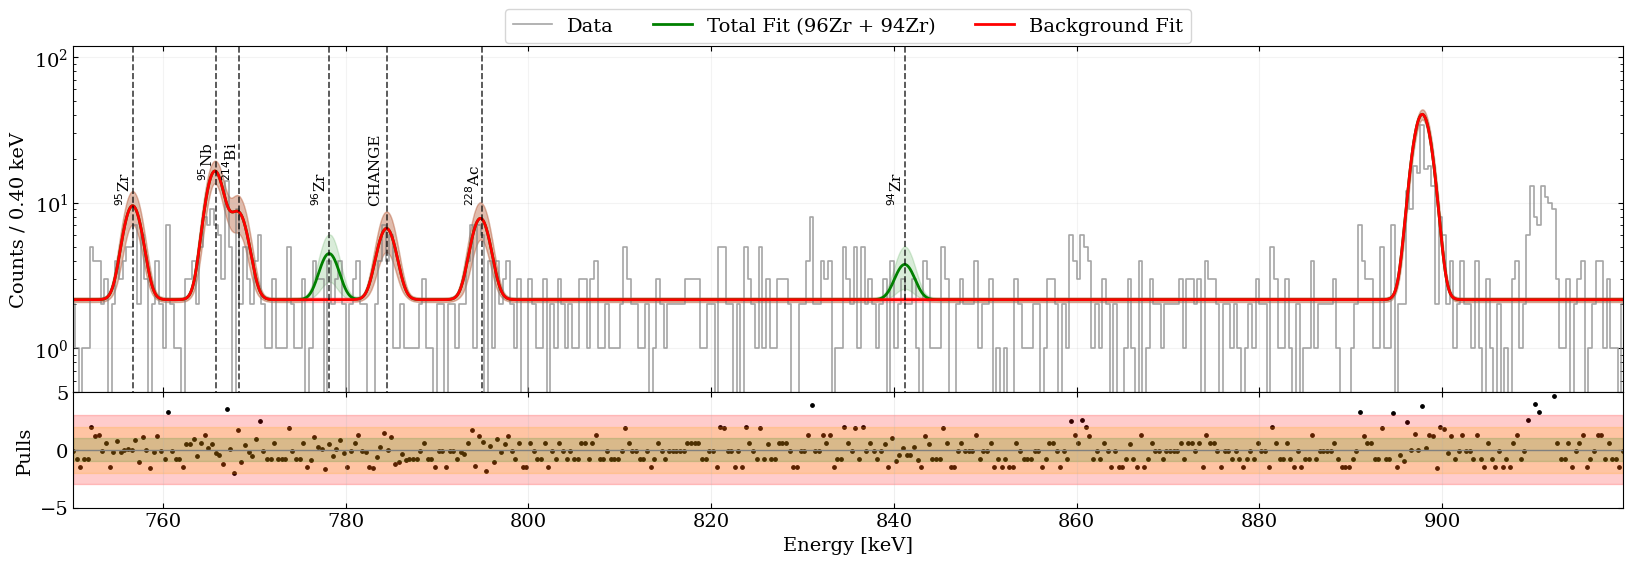

In [89]:

# ============================================================
# FIGURE
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
    figsize=(20, 6)
)

# ============================================================
# SAFETY CHECK
# ============================================================
assert E_fine.shape[0] == lambda_total_mean.shape[0]
assert E_roi.shape[0] == counts_roi.shape[0]

# ============================================================
# DATA
# ============================================================
ax1.step(
    E_roi,
    counts_roi,
    where="mid",
    color="grey",
    alpha=0.7,
    label="Data"
)

# ============================================================
# TOTAL FIT
# ============================================================
ax1.plot(
    E_fine,
    lambda_total_mean,
    color="green",
    lw=2,
    label="Total Fit (96Zr + 94Zr)"
)

ax1.fill_between(
    E_fine,
    lambda_total_low,
    lambda_total_high,
    color="green",
    alpha=0.15
)

# ============================================================
# BACKGROUND
# ============================================================
ax1.plot(
    E_fine,
    lambda_bkg_fine_mean,
    color="red",
    lw=2,
    label="Background Fit"
)

ax1.fill_between(
    E_fine,
    lambda_bkg_fine_low,
    lambda_bkg_fine_high,
    color="red",
    alpha=0.2
)

# ============================================================
# AXES
# ============================================================
ax1.set_yscale("log")

ax1.set_ylim(0.5, 120)

ax1.set_xlim(E_roi.min(), E_roi.max())

ax1.set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")

ax1.grid(alpha=0.15)

ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=3
)

# ============================================================
# PEAK LABELS
# ============================================================
add_peak(ax1, 778.2, r"$^{96}$Zr", 10)
add_peak(ax1, 841.2, r"$^{94}$Zr", 10)

add_peak(ax1, 756.73, r"$^{95}$Zr", 10)
add_peak(ax1, 768.4, r"$^{214}$Bi", 15)
add_peak(ax1, 765.8, r"$^{95}$Nb", 15)
add_peak(ax1, 784.5, r"CHANGE", 10)
add_peak(ax1, 794.947, r"$^{228}$Ac", 10)

# ============================================================
# RESIDUALS
# ============================================================
ax2.scatter(
    E_roi,
    residuals,
    s=6,
    color="black"
)

ax2.axhspan(-3, 3, color="red", alpha=0.2)
ax2.axhspan(-2, 2, color="orange", alpha=0.2)
ax2.axhspan(-1, 1, color="green", alpha=0.15)

ax2.axhline(0, color="gray", lw=1)

ax2.set_xlabel("Energy [keV]")
ax2.set_ylabel("Pulls")
ax2.set_ylim(-5, 5)

ax2.grid(alpha=0.2)

plt.subplots_adjust(hspace=0)

plt.show()